Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_1 (LSTM)               (None, 64)                17408     
                                                                 
 dense_1 (Dense)             (None, 1)                 65        
                                                                 
Total params: 17,473
Trainable params: 17,473
Non-trainable params: 0
_________________________________________________________________
Epoch 1/100
5/5 [==============================] - 3s 161ms/step - loss: 0.2617 - val_loss: 0.0448
Epoch 2/100
5/5 [==============================] - 0s 12ms/step - loss: 0.1235 - val_loss: 0.0353
Epoch 3/100
5/5 [==============================] - 0s 12ms/step - loss: 0.0778 - val_loss: 0.0546
Epoch 4/100
5/5 [==============================] - 0s 12ms/step - loss: 0.0823 - val_loss: 0.0495
Epoch 5/100
5/5 [==============================] - 0s

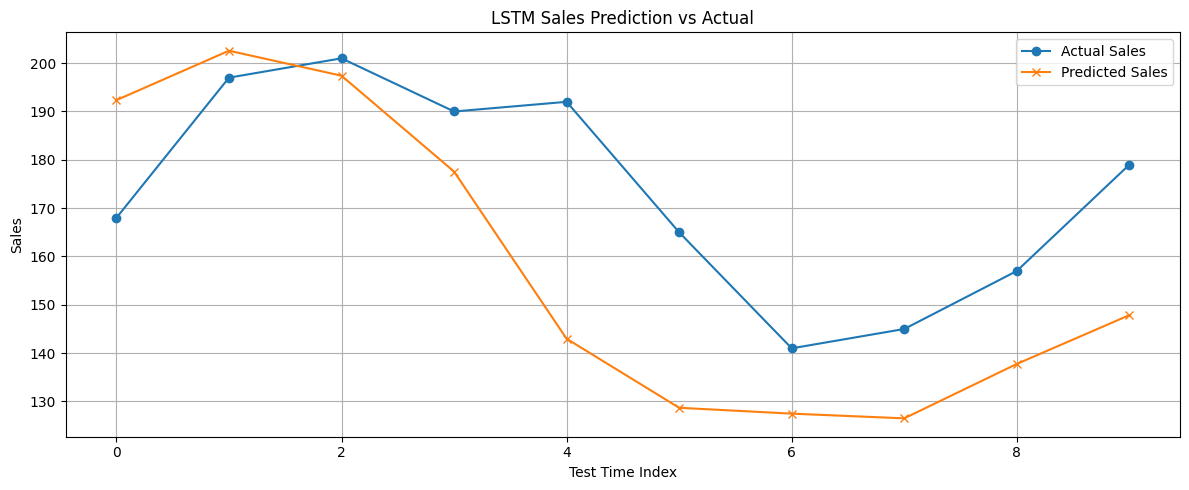

1/1 [==============================] - 0s 20ms/step
다음 달 예상 판매량: 140.59


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1. 데이터 불러오기
df = pd.read_csv("ice_cream_sales_data.csv", parse_dates=['Month'])

# 2. feature 및 target 설정
features = ['Temperature', 'Holidays', 'Promotion']
target = 'Sales'

# 3. 정규화
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(df[features])
y_scaled = scaler_y.fit_transform(df[[target]])

# 4. 시퀀스 생성 함수 (ex: 12개월 → 다음 달 예측)
def create_sequences(X, y, time_steps=12):
    Xs, ys = [], []
    for i in range(len(X) - time_steps):
        Xs.append(X[i:i+time_steps])
        ys.append(y[i+time_steps])
    return np.array(Xs), np.array(ys)

X_seq, y_seq = create_sequences(X_scaled, y_scaled)

# 5. 학습/테스트 분리 (80% 학습)
split = int(0.8 * len(X_seq))
X_train, X_test = X_seq[:split], X_seq[split:]
y_train, y_test = y_seq[:split], y_seq[split:]

# 6. LSTM 모델 정의
model = Sequential([
    LSTM(64, activation='tanh', input_shape=(X_seq.shape[1], X_seq.shape[2])),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.summary()

# 7. 학습
history = model.fit(X_train, y_train, epochs=100, batch_size=8, validation_split=0.1, verbose=1)

# 8. 예측
y_pred = model.predict(X_test)
y_pred_inv = scaler_y.inverse_transform(y_pred)
y_test_inv = scaler_y.inverse_transform(y_test)

# 9. 시각화
plt.figure(figsize=(12,5))
plt.plot(range(len(y_test_inv)), y_test_inv, label='Actual Sales', marker='o')
plt.plot(range(len(y_pred_inv)), y_pred_inv, label='Predicted Sales', marker='x')
plt.title("LSTM Sales Prediction vs Actual")
plt.xlabel("Test Time Index")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 10. 마지막 12개월을 기반으로 다음 달 예측
last_seq = X_scaled[-12:].reshape(1, 12, len(features))
next_pred_scaled = model.predict(last_seq)
next_pred = scaler_y.inverse_transform(next_pred_scaled)
print(f"다음 달 예상 판매량: {next_pred[0][0]:.2f}")
